## 12.3 子图流式运行
只需要在父图调用 **`stream`** 时传递 **`subgraphs=True`** 即可，这样父图和子图的流数据都会汇入同一个流队列，再通过命名空间区分来源。

**需要注意的是**：**`subgraphs=True`** 是在原有父图流数据的基础上，**额外加入子图内部产生的流数据**，并不会用子图数据替代父图数据。它会同时流式返回父图和所有子图的输出。

源代码:

```python
    def stream(
        self,
        input: InputT | Command | None,
        config: RunnableConfig | None = None,
        *,
        context: ContextT | None = None,
        stream_mode: StreamMode | Sequence[StreamMode] | None = None,
        print_mode: StreamMode | Sequence[StreamMode] = (),
        output_keys: str | Sequence[str] | None = None,
        interrupt_before: All | Sequence[str] | None = None,
        interrupt_after: All | Sequence[str] | None = None,
        durability: Durability | None = None,
        control: RunControl | None = None,
        subgraphs: bool = False,
        debug: bool | None = None,
        version: Literal["v2"],
        **kwargs: Unpack[DeprecatedKwargs],
    ) -> Iterator[StreamPart[StateT, OutputT]]
```

源码中 `stream()` 有两个重载：上面贴出的是 `version="v2"` 的版本，返回 `Iterator[StreamPart]`；不传 `version` 时为 `"v1"`，返回 `Iterator[dict | Any]`。本笔记的示例都使用 `"v1"`。

**参数说明：**

`*` 之前的 `input`、`config` 可以按位置传入；`*` 之后的参数必须写参数名。

| 参数 | 默认值 | 含义 |
|---|---|---|
| `input` | 必填 | 图的输入。可以是状态字典；`Command` 对象，如用 `Command(resume=...)` 恢复中断；或 `None`，表示不加新输入，从当前检查点继续运行。 |
| `config` | `None` | 运行配置。常用 `{"configurable": {"thread_id": ...}}` 指定线程，也可设置 `recursion_limit` 等。 |
| `context` | `None` | 本次运行的静态上下文，如用户 ID、数据库连接。需与图的 `context_schema` 对应，节点中通过 `runtime.context` 读取，不写入状态。 |
| `stream_mode` | `None` | 流模式，可传单个字符串或列表，取值见下表。为 `None` 时，`StateGraph` 编译出的图默认 `"updates"`；子图在父图节点内被调用时默认 `"values"`。 |
| `print_mode` | `()` | 取值同 `stream_mode`，只把对应数据打印到控制台，用于调试，不影响返回的流数据。 |
| `output_keys` | `None` | 只输出哪些状态字段，默认全部。 |
| `interrupt_before` | `None` | 在这些节点执行前暂停（静态断点），`"*"` 表示所有节点；为 `None` 时使用编译时的设置。 |
| `interrupt_after` | `None` | 在这些节点执行后暂停，其余同 `interrupt_before`。 |
| `durability` | `None` | 检查点的写入时机：`"sync"` 在下一步开始前同步写入；`"async"`（默认）在下一步执行的同时异步写入；`"exit"` 只在图结束时写入。没有存储器时无效。 |
| `control` | `None` | `RunControl` 对象，用于请求“排空”：调用 `control.request_drain()` 后，图在当前超步结束时停下并保存检查点，抛出 `GraphDrained`，之后可以恢复。常用于服务关闭。 |
| `subgraphs` | `False` | 是否同时输出子图内部的流数据。为 `True` 时，每条数据都会带上命名空间。 |
| `debug` | `None` | 为 `True` 时相当于 `print_mode=["updates", "values"]`，打印每一步的更新和状态。 |
| `version` | `"v1"` | 流数据格式：`"v1"` 输出元组或字典；`"v2"` 统一输出带 `type`、`ns`、`data` 键的字典。 |
| `**kwargs` | — | 已弃用的旧参数，如 `checkpoint_during`（已由 `durability` 取代），使用时会给出弃用警告。 |

`stream_mode` 的取值：

| 模式 | 每条数据的内容 |
|---|---|
| `"values"` | 每个超步结束后的完整状态 |
| `"updates"` | 每个超步中各节点返回的更新：`{节点名: 更新}` |
| `"messages"` | LLM 逐 token 的输出：`(消息块, 元数据)` |
| `"custom"` | 节点内通过 `StreamWriter` 写出的自定义数据 |
| `"checkpoints"` | 每次创建检查点时的事件，格式同 `get_state()` |
| `"tasks"` | 任务开始和结束的事件，包含结果和错误 |
| `"debug"` | `"checkpoints"` 和 `"tasks"` 的事件合并输出，用于调试 |

**返回值：** 一个迭代器，用 `for chunk in graph.stream(...)` 逐条取出流数据。调用 `stream()` 时图还没有运行，开始遍历才会执行。

`"v1"`（默认）下，每条 `chunk` 的形状由 `stream_mode` 是否为列表、`subgraphs` 是否为 `True` 决定：

| `stream_mode` 的形式 | `subgraphs=False` | `subgraphs=True` |
|---|---|---|
| 字符串，如 `"updates"` | `data` | `(namespace, data)` |
| 列表，如 `["updates"]` | `(mode, data)` | `(namespace, mode, data)` |

- `namespace`：元组，表示数据来源。父图为 `()`，子图为 `("<父图节点名>:<任务ID>",)`，规则见 12.3.1 的命名空间表。
- `mode`：这条数据属于哪种流模式。
- `data`：数据本身，内容见上面的流模式表。

本笔记使用 `stream_mode=["updates"]` 加 `subgraphs=True`，所以每条 `chunk` 都是三元组。

`"v2"` 下，无论参数怎样组合，每条数据都是同一种字典（源码中的 `StreamPart`）：

```python
{"type": "updates", "ns": (), "data": {"call_sub": {"text": "hi!"}}}
# values 模式额外带 interrupts 字段
{"type": "values", "ns": (), "data": {"text": "hi!"}, "interrupts": ()}
```

用 `chunk["type"]` 区分流模式，用 `chunk["ns"]` 区分来源，不必再按元组长度拆包。

### 12.3.1 分析`chunk`格式
格式:
```text
(namespace, stream_mode, data)
```

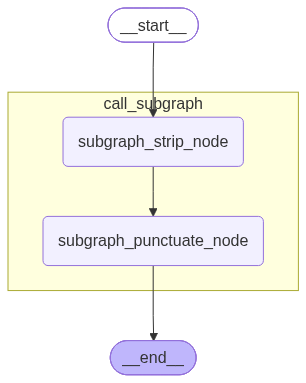

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# 构建子图
class SubgraphState(TypedDict):
    raw_text: str # 未清洗文本
    stripped_text: str # 去除收尾空格的文本
    punctuated_text: str # 句尾添加句号的文本

def subgraph_strip_node(state: SubgraphState) -> SubgraphState:
    raw_text = state["raw_text"]
    stripped_text = raw_text.strip()

    return {
        "stripped_text": stripped_text
    }

def subgraph_punctuate_node(state: SubgraphState) -> SubgraphState:
    stripped_text = state["stripped_text"]
    punctuated_text = stripped_text + "。"

    return {
        "punctuated_text": punctuated_text
    }

builder = StateGraph(state_schema=SubgraphState)
builder.add_node("subgraph_strip_node", subgraph_strip_node)
builder.add_node("subgraph_punctuate_node", subgraph_punctuate_node)

builder.add_edge(START, "subgraph_strip_node")
builder.add_edge("subgraph_strip_node", "subgraph_punctuate_node")
builder.add_edge("subgraph_punctuate_node", END)

subgraph = builder.compile()

# 构建父图
class ParentState(TypedDict):
    input_text: str # 输入的未清洗的文本
    cleaned_text: str # 清洗后的文本

def call_subgraph(state: ParentState) -> ParentState:
    input_text = state["input_text"]

    res = subgraph.invoke({"raw_text": input_text})
    cleaned_text = res["punctuated_text"]
    return {
        "cleaned_text": cleaned_text
    }

builder = StateGraph(state_schema=ParentState)
builder.add_node("call_subgraph", call_subgraph)

builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

parent_graph = builder.compile()
from IPython.display import display, Image
display(
    Image(
        parent_graph
        .get_graph(xray=True)
        .draw_mermaid_png()
    )
)

In [2]:
from rich import print as rprint

input_text = "   LangGraph 真有意思        "
for chunk in parent_graph.stream(
    {"input_text": input_text},
    subgraphs=True,
    stream_mode=["updates"]
):
    rprint(chunk)

(
    ('call_subgraph:20872bf4-80c4-8d3f-50d1-6586273c1089',),
    'updates',
    {'subgraph_strip_node': {'stripped_text': 'LangGraph 真有意思'}}
)

(
    ('call_subgraph:20872bf4-80c4-8d3f-50d1-6586273c1089',),
    'updates',
    {'subgraph_punctuate_node': {'punctuated_text': 'LangGraph 真有意思。'}}
)

((), 'updates', {'call_subgraph': {'cleaned_text': 'LangGraph 真有意思。'}})

**流数据命名空间规则**：

| 来源               | 命名空间                       | 备注                 |
| :----------------- | :----------------------------- | :------------------- |
| 父图               | `()`（空元组）                 |                      |
| 子图（常规）       | `(<父图节点名>:<父图任务ID>,)` |                      |
| 子图（Per-thread） | `(<父图节点名>,)`              | 与检查点命名空间一致 |

### 12.3.2. 多轮对话消息流处理

In [10]:
import os
from typing import TypedDict
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from langchain.messages import HumanMessage, SystemMessage, AIMessage
import sys
from loguru import logger
# 删除 Loguru 默认的 stderr sink
logger.remove()
# 重新添加支持颜色的 sink
logger.add(sys.stdout, colorize=True)

from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

In [11]:
# 构建子图
class SubgraphState(MessagesState):
    system_prompt: SystemMessage

def llm_mode(state: SubgraphState) -> SubgraphState:
    system_prompt = state["system_prompt"]
    messages = state["messages"]

    response = model.invoke([system_prompt] + messages)
    return {
        "messages": [response]
    }

builder = StateGraph(state_schema=SubgraphState)
builder.add_node("llm_mode", llm_mode)
builder.add_edge(START, "llm_mode")
builder.add_edge("llm_mode", END)
subgraph = builder.compile(checkpointer=True)

In [12]:
from rich import print as rprint
# 构建父图
class ParentState(TypedDict):
    user_input: str
    assistant_response: str
# 函数中调用子图
def call_subgraph(state: ParentState) -> ParentState:
    user_input = state["user_input"]

    response = subgraph.invoke(
        {
            "system_prompt": SystemMessage("你是个善解人意的助手"),
            "messages": [HumanMessage(user_input)]
        }
    )

    assistant_response = response["messages"][-1].content

    return {
        "assistant_response": assistant_response
    }

builder = StateGraph(state_schema=ParentState)
builder.add_node("call_subgraph", call_subgraph)
builder.add_edge(START, "call_subgraph")
builder.add_edge("call_subgraph", END)

checkpointer = InMemorySaver()
parent_graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "subgraph_stream_test"}}

print("\n", "=" * 30, "-> 第一次运行结果 <-", "=" * 30)
for chunk in parent_graph.stream(
    {
        "user_input": "花儿为什么这样红？"
    },
    config=config,
    subgraphs=True,
    stream_mode=["values"]
):
    rprint(chunk)


 ============================== -> 第一次运行结果 <- ==============================


((), 'values', {'user_input': '花儿为什么这样红？'})

(
    ('call_subgraph',),
    'values',
    {
        'messages': [
            HumanMessage(
                content='花儿为什么这样红？',
                additional_kwargs={},
                response_metadata={},
                id='35b9e15c-b66d-41ad-82e2-dd3e0c636b23'
            )
        ],
        'system_prompt': SystemMessage(
            content='你是个善解人意的助手',
            additional_kwargs={},
            response_metadata={}
        )
    }
)

(
    ('call_subgraph',),
    'values',
    {
        'messages': [
            HumanMessage(
                content='花儿为什么这样红？',
                additional_kwargs={},
                response_metadata={},
                id='35b9e15c-b66d-41ad-82e2-dd3e0c636b23'
            ),
            AIMessage(
                content='花儿之所以呈现红色，是因为花瓣细胞里有能吸收部分可见光的色素，剩下反射或透出的红光进入我们
的眼睛。\n\n常见的红色色素是花青素。它的颜色还会受细胞液的酸碱度、色素浓度和细胞结构影响，所以同一种花也可能呈现深
红、粉红或紫红。花色往往还能吸引传粉动物；不同动物对颜色的感知不同，有些花甚至在紫外线下会显出人眼看不到的图案。',
                additional_kwargs={'refusal': None},
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 136,
                        'prompt_tokens': 4405,
                        'total_tokens': 4541,
                        'completion_tokens_details': None,
                        'prompt_tokens_details': {
                            'audio_tokens': None,
                            'cache_write_tokens': None,
                            'cached_tokens': 4224,
                            'image_tokens': None,
                            'text_tokens': None
                        }
                    },
                    'model_provider': 'openai',
                    'model_name': 'gpt-6-sol',
                    'system_fingerprint': None,
                    'id': 'resp_089ae2aac22696c8016ad860d0f3a4819886b19f66d8b36053',
                    'service_tier': 'default',
                    'finish_reason': 'stop',
                    'logprobs': None
                },
                id='lc_run--01a15d3a-0343-7469-88a1-04c884651543-0',
                tool_calls=[],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 4405,
                    'output_tokens': 136,
                    'total_tokens': 4541,
                    'input_token_details': {'cache_read': 4224},
                    'output_token_details': {}
                }
            )
        ],
        'system_prompt': SystemMessage(
            content='你是个善解人意的助手',
            additional_kwargs={},
            response_metadata={}
        )
    }
)

(
    (),
    'values',
    {
        'user_input': '花儿为什么这样红？',
        'assistant_response': 
'花儿之所以呈现红色，是因为花瓣细胞里有能吸收部分可见光的色素，剩下反射或透出的红光进入我们的眼睛。\n\n常见的红色色
素是花青素。它的颜色还会受细胞液的酸碱度、色素浓度和细胞结构影响，所以同一种花也可能呈现深红、粉红或紫红。花色往往
还能吸引传粉动物；不同动物对颜色的感知不同，有些花甚至在紫外线下会显出人眼看不到的图案。'
    }
)

In [9]:
print("\n", "=" * 30, "-> 第二次运行结果 <-", "=" * 30)
for chunk in parent_graph.stream(
    {
        "user_input": "刚才我们聊了什么？"
    },
    config=config,
    subgraphs=True,
    stream_mode=["values"]
):
    rprint(chunk)



 ============================== -> 第二次运行结果 <- ==============================


(
    (),
    'values',
    {
        'user_input': '刚才我们聊了什么？',
        'assistant_response': 
'花儿呈现红色，主要是因为花瓣里的色素会选择性地吸收和反射光。红色花瓣常含有花青素：它吸收较多蓝绿光，把红光反射或透
射出来，所以我们看到红色。酸碱度、光照和花瓣细胞结构也会影响红色的深浅。\n\n从生物学上说，鲜艳的红色还能吸引传粉者
，帮助植物繁殖。不同植物演化出了不同的色素和颜色，因此花色各异。'
    }
)

(
    ('call_subgraph',),
    'values',
    {
        'messages': [
            HumanMessage(
                content='花儿为什么这样红？',
                additional_kwargs={},
                response_metadata={},
                id='bf9c7e0e-28cf-4619-9a9e-88f870893e8c'
            ),
            AIMessage(
                content='花儿呈现红色，主要是因为花瓣里的色素会选择性地吸收和反射光。红色花瓣常含有花青素：它吸收较
多蓝绿光，把红光反射或透射出来，所以我们看到红色。酸碱度、光照和花瓣细胞结构也会影响红色的深浅。\n\n从生物学上说，
鲜艳的红色还能吸引传粉者，帮助植物繁殖。不同植物演化出了不同的色素和颜色，因此花色各异。',
                additional_kwargs={'refusal': None},
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 127,
                        'prompt_tokens': 4405,
                        'total_tokens': 4532,
                        'completion_tokens_details': None,
                        'prompt_tokens_details': {
                            'audio_tokens': None,
                            'cache_write_tokens': None,
                            'cached_tokens': 4224,
                            'image_tokens': None,
                            'text_tokens': None
                        }
                    },
                    'model_provider': 'openai',
                    'model_name': 'gpt-6-sol',
                    'system_fingerprint': None,
                    'id': 'resp_0cddae887acd0e56016ad85fb3e9808194bbf7be974ae8ab90',
                    'service_tier': 'default',
                    'finish_reason': 'stop',
                    'logprobs': None
                },
                id='lc_run--01a15d35-d102-7194-99d2-2ac586969eaa-0',
                tool_calls=[],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 4405,
                    'output_tokens': 127,
                    'total_tokens': 4532,
                    'input_token_details': {'cache_read': 4224},
                    'output_token_details': {}
                }
            ),
            HumanMessage(
                content='刚才我们聊了什么？',
                additional_kwargs={},
                response_metadata={},
                id='da2e81be-c33e-48d0-8139-ac8c2bdf8539'
            ),
            HumanMessage(
                content='刚才我们聊了什么？',
                additional_kwargs={},
                response_metadata={},
                id='a65cc6e1-7765-45f4-98f8-8f848f36c30c'
            ),
            HumanMessage(
                content='刚才我们聊了什么？',
                additional_kwargs={},
                response_metadata={},
                id='6d0256cc-57af-42fc-b09b-3456155879e5'
            )
        ],
        'system_prompt': SystemMessage(
            content='你是个善解人意的助手',
            additional_kwargs={},
            response_metadata={}
        )
    }
)

(
    ('call_subgraph',),
    'values',
    {
        'messages': [
            HumanMessage(
                content='花儿为什么这样红？',
                additional_kwargs={},
                response_metadata={},
                id='bf9c7e0e-28cf-4619-9a9e-88f870893e8c'
            ),
            AIMessage(
                content='花儿呈现红色，主要是因为花瓣里的色素会选择性地吸收和反射光。红色花瓣常含有花青素：它吸收较
多蓝绿光，把红光反射或透射出来，所以我们看到红色。酸碱度、光照和花瓣细胞结构也会影响红色的深浅。\n\n从生物学上说，
鲜艳的红色还能吸引传粉者，帮助植物繁殖。不同植物演化出了不同的色素和颜色，因此花色各异。',
                additional_kwargs={'refusal': None},
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 127,
                        'prompt_tokens': 4405,
                        'total_tokens': 4532,
                        'completion_tokens_details': None,
                        'prompt_tokens_details': {
                            'audio_tokens': None,
                            'cache_write_tokens': None,
                            'cached_tokens': 4224,
                            'image_tokens': None,
                            'text_tokens': None
                        }
                    },
                    'model_provider': 'openai',
                    'model_name': 'gpt-6-sol',
                    'system_fingerprint': None,
                    'id': 'resp_0cddae887acd0e56016ad85fb3e9808194bbf7be974ae8ab90',
                    'service_tier': 'default',
                    'finish_reason': 'stop',
                    'logprobs': None
                },
                id='lc_run--01a15d35-d102-7194-99d2-2ac586969eaa-0',
                tool_calls=[],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 4405,
                    'output_tokens': 127,
                    'total_tokens': 4532,
                    'input_token_details': {'cache_read': 4224},
                    'output_token_details': {}
                }
            ),
            HumanMessage(
                content='刚才我们聊了什么？',
                additional_kwargs={},
                response_metadata={},
                id='da2e81be-c33e-48d0-8139-ac8c2bdf8539'
            ),
            HumanMessage(
                content='刚才我们聊了什么？',
                additional_kwargs={},
                response_metadata={},
                id='a65cc6e1-7765-45f4-98f8-8f848f36c30c'
            ),
            HumanMessage(
                content='刚才我们聊了什么？',
                additional_kwargs={},
                response_metadata={},
                id='6d0256cc-57af-42fc-b09b-3456155879e5'
            ),
            AIMessage(
                content='你问“花儿为什么这样红？”，我解释了花瓣中的色素会吸收和反射不同颜色的光，常见的花青素让花呈
现红色；鲜艳的花色也能吸引传粉者。',
                additional_kwargs={'refusal': None},
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 59,
                        'prompt_tokens': 4567,
                        'total_tokens': 4626,
                        'completion_tokens_details': None,
                        'prompt_tokens_details': {
                            'audio_tokens': None,
                            'cache_write_tokens': None,
                            'cached_tokens': 4224,
                            'image_tokens': None,
                            'text_tokens': None
                        }
                    },
                    'model_provider': 'openai',
                    'model_name': 'gpt-6-sol',
                    'system_fingerprint': None,
                    'id': 'resp_02b81d75b3acd9fe016ad8603f9b188196a6fe24121c394323',
                    'service_tier': 'default',
                    'finish_reason': 'stop',
                    'logprobs': None
                },
                id='lc_run--01a15d37-5c4f-7534-9d41-a63e2eb384c1-0',
                tool_calls=[],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 

(
    (),
    'values',
    {
        'user_input': '刚才我们聊了什么？',
        'assistant_response': 
'你问“花儿为什么这样红？”，我解释了花瓣中的色素会吸收和反射不同颜色的光，常见的花青素让花呈现红色；鲜艳的花色也能吸
引传粉者。'
    }
)

## 12.4 子图动态路由
在子图中可以通过 **`Command`** 动态路由到父图节点，只要将参数 **`graph`** 的值设置为 **`Command.PARENT`** 即可，如下所示

```python
return Command(
    update={
        "fruits": fruits,
        "vegetables": vegetables
    },
    goto="router_node",
    graph=Command.PARENT
)
```

Command 源码函数:
```python
Command(
  self,
  *,
  graph: str | None = None,
  update: Any | None = None,
  resume: dict[str, Any] | Any | None = None,
  goto: Send | Sequence[Send | N] | N = ()
)
```

`Command` 是一个数据类，调用 `Command(...)` 就是创建一个命令对象。签名中的 `*` 表示所有参数都必须写参数名。

**参数说明：**

| 参数 | 默认值 | 含义 |
|---|---|---|
| `graph` | `None` | 命令交给哪个图处理：`None` 表示当前图；`Command.PARENT`（值为 `"__parent__"`）表示最近的一层父图。 |
| `update` | `None` | 要写入状态的更新，通常是字典，如 `{"fruits": fruits}`；也可以是 `(键, 值)` 元组列表或状态类的实例。合并方式与节点返回值相同，带规约函数的字段按规约函数合并。 |
| `resume` | `None` | 恢复中断时交给 `interrupt()` 的值：单个值交给下一个待恢复的中断；字典 `{中断ID: 值}` 可以一次恢复多个中断。只在作为 `invoke()` / `stream()` 的输入时生效，写在节点返回值里会被忽略。 |
| `goto` | `()` | 接下来执行哪些节点：节点名、节点名列表、`Send` 对象或 `Send` 列表。节点名必须属于 `graph` 指定的图。 |

**返回值：** 一个 `Command` 对象。它本身不做任何事，交给 LangGraph 后才生效，有两种用法：

| 用法 | 写法 | 常用参数 |
|---|---|---|
| 作为节点的返回值 | `return Command(update=..., goto=...)` | `update`、`goto`、`graph` |
| 作为图的输入 | `graph.invoke(Command(resume=...), config)` | `resume`，也可带 `update`、`goto` |

使用时要注意：

- **`goto` 不会取消静态边**：节点 `a` 已有边 `a → b` 时，返回 `Command(goto="c")` 后 `b` 和 `c` 都会执行。
- **`graph=Command.PARENT` 时一切按父图来写**：本例子图节点返回的命令交给父图处理，`update` 写入父图状态，`goto` 跳转到父图节点 `node_b`。因此 `update` 的键和 `goto` 的节点名都要以父图为准。
- **作为图的输入时不能用 `Command.PARENT`**：最外层的图没有父图，会报错 `There is no parent graph`。

In [13]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command
from loguru import logger

# ==================== 子图 ====================
class SubState(TypedDict):
    data: str

def sub_node(state: SubState) -> Command:
    """子图节点：执行后动态路由回父图的 parent_router"""
    logger.info("[子图] sub_node 执行")
    return Command(
        update={"data": state["data"] + " → 子图"},
        goto="node_b",       # 路由到父图节点
        graph=Command.PARENT,       # 指定目标为父图
    )

sub_builder = StateGraph(state_schema=SubState)
sub_builder.add_node("sub_node", sub_node)
sub_builder.add_edge(START, "sub_node")
sub_graph = sub_builder.compile()

2026-10-21 00:20:53.345 | INFO     | __main__:sub_node:12 - [子图] sub_node 执行
[父图] node_b 执行


{'data': '初始 → 子图'}

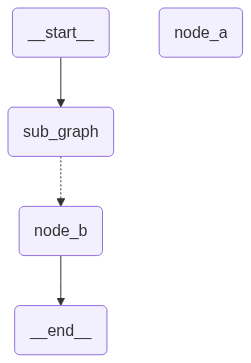

In [15]:
# ==================== 父图 ====================
class ParentState(TypedDict):
    data: str

def node_a(state: ParentState) -> ParentState:
    print("[父图] node_a 执行")
    return {"visited_a": True}

def node_b(state: ParentState) -> ParentState:
    print("[父图] node_b 执行")
    return {"visited_b": True}

parent_builder = StateGraph(state_schema=ParentState)
parent_builder.add_node(
    "sub_graph", sub_graph,
    destinations=("node_b",)
)

parent_builder.add_node("node_a", node_a)
parent_builder.add_node("node_b", node_b)
parent_builder.add_edge(START, "sub_graph")
parent_builder.add_edge("node_a", "node_b")
parent_builder.add_edge("node_b", END)
parent_graph = parent_builder.compile()

result = parent_graph.invoke({"data": "初始"})
rprint(result)

from IPython.display import display
display(parent_graph)